# Matched sensing pulse design

Specify known frequencies and a list of linear observables, find their shared
query subspace, compile pulses, and decode measured counts. Frequencies are in Hz;
times are in seconds. Three queries below share two measured coordinates.

In [8]:
from pathlib import Path
import sys
import importlib
import numpy as np
import matplotlib.pyplot as plt

# Works from the repository root, this notebook folder, or the parent workspace.
candidates = [p for parent in (Path.cwd(), *Path.cwd().parents)
              for p in (parent, parent / "Algorithmic_Sensing_Toolkit")]
ROOT = next(p for p in candidates if (p / "src/matched_sensing").is_dir())
sys.path.insert(0, str(ROOT / "src"))

# Refresh the whole local package when this kernel has an older version cached.
for name in tuple(sys.modules):
    if name == "matched_sensing" or name.startswith("matched_sensing."):
        del sys.modules[name]
importlib.invalidate_caches()
from matched_sensing import (Experiment, query_space, compile_queries, audit, plan_queries,
                            export_bundle, load_bundle, simulate_queries, write_counts,
                            read_counts, decode_queries)

## 1. Specify the experiment

The field is $b(t)=\sum_j[a_j\cos(2\pi f_jt)+b_j\sin(2\pi f_jt)]$.
Supply every possible input frequency, including unwanted tones. Each row of
`cosine_weights` and `sine_weights` defines one desired observable:
$F_j=K_j^T A$, with $A=[a_1,\ldots,a_N,b_1,\ldots,b_N]$.

This example uses two independent queries and their combination $F_3=F_1+2F_2$.
Edit these arrays for your own queries. Pulses are ideal instantaneous X(pi)
rotations. Timing limits and the joint amplitude norm bound are set below.

In [9]:
#Linear Observables you want to estimate
cosine_weights = np.array([[0.5, -0.3, 0.0, 0.4],
                           [0.1,  0.2, -0.4, 0.3]])
sine_weights = np.array([[0.2, 0.4, 0.1, -0.2],
                         [-0.3, 0.1, 0.2, 0.25]])
# Add a dependent query to demonstrate measurement sharing.
cosine_weights = np.vstack([cosine_weights, cosine_weights[0] + 2*cosine_weights[1]])
sine_weights = np.vstack([sine_weights, sine_weights[0] + 2*sine_weights[1]])

experiment = Experiment(
    frequencies_hz=(0.8e6, 1.05e6, 1.31e6, 1.72e6), # known frequencies
    cosine_weights=cosine_weights, # one row per desired observable
    sine_weights=sine_weights,     # rows match the cosine weights
    coupling_hz=100e3,       # H = (2*pi*coupling_hz)*b(t)*Z/2
    t2_s=200e-6,            # None gives no dephasing
    amplitude_bound=1.0,    # Upper bound on the combined norm of all unknown cosine and sine amplitudes
    min_gap_s=20e-9,        # spacing between the pulses
    edge_guard_s=20e-9,     # time between sequence start to its first pulse and from last pulse to sequence end
    clock_s=None,           # grid for pulse timing, None means pulse timings can vary continuously
    visibility=1.0,         # calibrated readout visibility before dephasing
    readout_bias=0.0,       # calibrated additive offset of the +/-1 mean
    overhead_s=0.0,         # preparation/reset/readout overhead per shot
)

### Shared query coordinates

SVD finds $U$ with orthonormal columns spanning the query directions. Define
$\kappa=\max_j\|K_j\|_2$ and $v_j=U^T K_j/\kappa$. Then
$K_j/\kappa=Uv_j$, $y=U^TA$, and $F_j=\kappa v_j^T y$.
We measure the $r$ coordinates of $y$ once and reuse them for every query.
Numerical rank residuals are included in the accuracy budget.

In [10]:
space = query_space(experiment)
U = np.array(space.basis)
v = np.array(space.coefficients)  # row j is v_j
print(f"Queries: {space.count}; shared rank r: {space.rank}; kappa: {space.kappa:.6g}")
print("U =\n", U.round(4))
print("v_j (rows) =\n", v.round(4))
print("Maximum reconstruction residual:", np.max(abs(experiment.weights - space.kappa*v@U.T)))

Queries: 3; shared rank r: 2; kappa: 1.73205
U =
 [[ 0.4229 -0.4021]
 [ 0.0364  0.4685]
 [-0.4464 -0.3496]
 [ 0.5839 -0.1295]
 [-0.2103 -0.458 ]
 [ 0.3606 -0.3042]
 [ 0.2855  0.0769]
 [ 0.1545  0.4143]]
v_j (rows) =
 [[ 0.3083 -0.3937]
 [ 0.3454  0.2196]
 [ 0.999   0.0456]]
Maximum reconstruction residual: 2.220446049250313e-16


## 2. Compile and inspect pulses

Set the maximum gain, sequence duration, and pulse count. The compiler generates
smaller candidates automatically and keeps the shortest passing duration per gain.
Each accepted control is reintegrated over all Fourier coordinates and checked
against the timing constraints, including the minimum pulse gap. These limits
bound a finite search; failure does not establish physical impossibility.

`start_time_s` is relative to the field's phase origin. Replaying a waveform
requires the same tone phases at each trigger; use phase-locked triggering or
recompile for the new reference time. Arbitrary frequency spacings are allowed.
See [the model](../docs/model.md) for the automatic candidate grids.

In [11]:
bank = compile_queries(
    experiment,
    max_gain=4.0,
    max_duration_s=40e-6,
    max_pulses=128,
    start_time_s=123e-9,
    phase_tolerance=1e-3,
    seed=4,
)
print("coordinate   gain   duration (us)   pulses   phase error   minimum gap (ns)")
for i, coordinate_bank in enumerate(bank.banks):
    for sequence in coordinate_bank.sequences:
        check = audit(coordinate_bank.experiment, sequence)
        gap = check["minimum_gap_s"]
        print(f"{i:10d}   {sequence.gain:4g}   {sequence.duration_s*1e6:13.3f}   "
              f"{len(sequence.switch_times_s):6d}   {sequence.phase_error_bound:11.2g}   "
              f"{gap*1e9 if gap is not None else float('nan'):16.3f}")

coordinate   gain   duration (us)   pulses   phase error   minimum gap (ns)
         0    0.5          10.000       32       2.6e-09            238.979
         0      1          10.000       32       2.4e-10            233.624
         0      2          10.000       32       3.2e-10            169.181
         0      4          20.000       32       4.9e-09            294.684
         1    0.5          10.000       32         6e-10             24.896
         1      1          10.000       32       3.9e-10            186.699
         1      2          10.000       32       4.7e-09            146.773
         1      4          20.000       32       8.6e-10            274.785


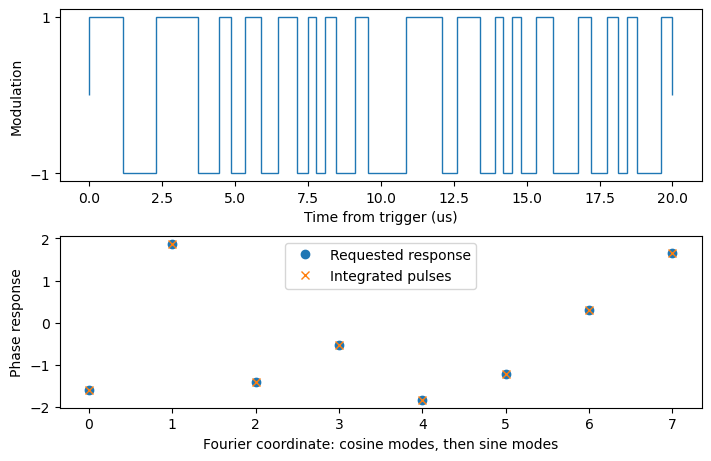

In [12]:
coordinate = 1  # choose the shared query coordinate to inspect
coordinate_bank = bank.banks[coordinate]
sequence = coordinate_bank.sequences[-1]  # choose which gain to inspect
edges = np.r_[0.0, sequence.switch_times_s, sequence.duration_s]
fig, axes = plt.subplots(2, 1, figsize=(7, 4.5), constrained_layout=True)
axes[0].stairs((-1.0)**np.arange(len(edges)-1), edges*1e6)
axes[0].set(xlabel="Time from trigger (us)", ylabel="Modulation", yticks=[-1, 1])
k = np.arange(len(coordinate_bank.experiment.weights))
axes[1].plot(k, coordinate_bank.experiment.target(sequence.gain), "o", label="Requested response")
axes[1].plot(k, sequence.phase_vector, "x", label="Integrated pulses")
axes[1].set(xlabel="Fourier coordinate: cosine modes, then sine modes", ylabel="Phase response")
axes[1].legend()
plt.show()

## 3. Choose gains and repetitions

`precision` is an absolute error in the original units, supplied as a scalar or
one value per query. `confidence` holds for **all queries simultaneously**.
The planner splits the failure budget across shared coordinates and propagates
their intervals. This is conservative; it does not implement the manuscript's
optimal directional-variance allocation. Gains account for T2 and compilation
error. `max_shots` caps the total across all coordinates and both X/Y bases.
Use `optimize="with_overhead"` to charge the specified per-shot overhead.

In [13]:
plan = plan_queries(bank, precision=0.08, confidence=0.95,
                    max_shots=1_000_000, optimize="active")
for row in plan.rows:
    gain = bank.sequences[row["sequence_index"]].gain
    print(f"{row['row_id']:14s} gain={gain:g}  shots={row['shots']}  "
          f"contrast={row['contrast']:.3f}")
print("Coordinate precisions:", [p.precision for p in plan.coordinate_plans])
print("Per-query error bounds:", plan.error_bounds)
print(f"Active time: {plan.active_time_s*1e3:.2f} ms for all queries")
print(f"With specified overhead: {plan.time_with_overhead_s*1e3:.2f} ms")

q0_stage0_X    gain=2  shots=102  contrast=0.951
q0_stage0_Y    gain=2  shots=102  contrast=0.951
q0_stage1_X    gain=4  shots=911  contrast=0.905
q0_stage1_Y    gain=4  shots=911  contrast=0.905
q1_stage0_X    gain=2  shots=102  contrast=0.951
q1_stage0_Y    gain=2  shots=102  contrast=0.951
q1_stage1_X    gain=4  shots=911  contrast=0.905
q1_stage1_Y    gain=4  shots=911  contrast=0.905
Coordinate precisions: [0.04421954360579618, 0.04421954360579618]
Per-query error bounds: (0.05376103050056363, 0.04327122509868113, 0.08)
Active time: 76.96 ms for all queries
With specified overhead: 76.96 ms


## 4. Export the experiment

`pulses.csv` gives X(pi) times; `acquisition.csv` specifies the sequence, analysis
basis, and repetitions. Map these ideal operations to your calibrated hardware.
Read `RUN.txt` before acquisition. Fill a **copy** of `counts_template.csv` with
positive-outcome counts, preserving its plan ID and shot totals.

Rerunning this cell replaces generated plan files in `outputs/query_example`.
The template stays blank; keep your completed counts in a separate file.
`query_space.csv` and `query_coefficients.csv` record U, kappa, and the v_j rows.

In [14]:
output = export_bundle(plan, ROOT / "outputs/query_example", overwrite=True)
print("Exported:")
for name in ("pulses.csv", "intervals.csv", "acquisition.csv", "counts_template.csv",
             "query_space.csv", "query_coefficients.csv",
             "bundle.json", "manifest.json", "compilation.json", "RUN.txt"):
    print((output / name).relative_to(ROOT))

Exported:
outputs/query_example/pulses.csv
outputs/query_example/intervals.csv
outputs/query_example/acquisition.csv
outputs/query_example/counts_template.csv
outputs/query_example/query_space.csv
outputs/query_example/query_coefficients.csv
outputs/query_example/bundle.json
outputs/query_example/manifest.json
outputs/query_example/compilation.json
outputs/query_example/RUN.txt


## 5. Optional simulated counts

This cell makes a synthetic dense field and uses the actual compiled pulse
responses. The decoder below receives only counts and the saved plan. For a
hardware run, skip this cell and select your completed counts file in step 6.

In [15]:
rng = np.random.default_rng(4)
amplitudes = rng.normal(size=2*len(experiment.frequencies_hz))
amplitudes *= 0.7 * experiment.amplitude_bound / np.linalg.norm(amplitudes)
demo_counts = simulate_queries(plan, amplitudes, seed=42)
write_counts(output / "demo_counts.csv", plan, demo_counts)
print("Synthetic counts saved to outputs/query_example/demo_counts.csv")

Synthetic counts saved to outputs/query_example/demo_counts.csv


## 6. Decode your counts

The saved bundle is portable: it contains the inputs, pulse responses, readout
plan, and integrity hashes. Set `counts_file` to your completed hardware CSV.
The blank template is deliberately rejected by the loader.

In [16]:
counts_file = output / "demo_counts.csv"  # replace with your completed hardware CSV
saved_plan = load_bundle(output)
result = decode_queries(saved_plan, read_counts(counts_file, saved_plan))
for j, (value, interval) in enumerate(zip(result.values, result.intervals)):
    print(f"F{j+1}: {value:.6f}; interval: {interval}")
print(f"Simultaneous confidence: {100*result.confidence:g}%")
print("F3 - (F1 + 2*F2):", result.values[2] - result.values[0] - 2*result.values[1])

F1: -0.121145; interval: (-0.17490603977823413, -0.06738397877710683)
F2: -0.048612; interval: (-0.09188282636272238, -0.0053403761653601015)
F3: -0.218368; interval: (-0.29836821180575296, -0.1383682118057529)
Simultaneous confidence: 95%
F3 - (F1 + 2*F2): 1.3877787807814457e-17


The confidence statement assumes a fixed coherent field within the amplitude
bound, correct frequencies and phase reference, calibrated visibility/T2/bias,
and independent binary outcomes. Finite pulse evolution, timing jitter, and
calibration uncertainty are outside this model. The shared query-subspace factorization uses full coherent sensing;
the clipped-filter/residual protocol is not implemented.

See [model and timing conventions](../docs/model.md).